In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from ucimlrepo import fetch_ucirepo

PROJECT_ROOT = Path.cwd()

# Config view
pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)

sns.set_theme(style="whitegrid")

## Load dataset

In [2]:
# Dataset - UCI
dataset = fetch_ucirepo(id=350)

X = dataset.data.features
y = dataset.data.targets

df = pd.concat([X, y], axis=1)

if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

DATA_PATH = PROJECT_ROOT / "data" / "raw" / "credit_default.csv"
DATA_PATH.parent.mkdir(parents=True, exist_ok=True)

df.to_csv(DATA_PATH, index=False)

print(f"Dataset saved at: {DATA_PATH}")


Dataset saved at: /home/glaucia/credit-risk-prediction/data/raw/credit_default.csv


In [3]:
display(df.head())
df.info()
display(df.describe().T)

,X1,X2,X3,X4,X5,X6,X7,X8,X9,X10,X11,X12,X13,X14,X15,X16,X17,X18,X19,X20,X21,X22,X23,Y
0,20000,2,2,1,24,2,2,-1,-1,-2,-2,3913,3102,689,0,0,0,0,689,0,0,0,0,1
1,120000,2,2,2,26,-1,2,0,0,0,2,2682,1725,2682,3272,3455,3261,0,1000,1000,1000,0,2000,1
2,90000,2,2,2,34,0,0,0,0,0,0,29239,14027,13559,14331,14948,15549,1518,1500,1000,1000,1000,5000,0
3,50000,2,2,1,37,0,0,0,0,0,0,46990,48233,49291,28314,28959,29547,2000,2019,1200,1100,1069,1000,0
4,50000,1,2,1,57,-1,0,-1,0,0,0,8617,5670,35835,20940,19146,19131,2000,36681,10000,9000,689,679,0


<class 'pandas.DataFrame'>
RangeIndex: 30000 entries, 0 to 29999
Data columns (total 24 columns):
 #   Column  Non-Null Count  Dtype
---  ------  --------------  -----
 0   X1      30000 non-null  int64
 1   X2      30000 non-null  int64
 2   X3      30000 non-null  int64
 3   X4      30000 non-null  int64
 4   X5      30000 non-null  int64
 5   X6      30000 non-null  int64
 6   X7      30000 non-null  int64
 7   X8      30000 non-null  int64
 8   X9      30000 non-null  int64
 9   X10     30000 non-null  int64
 10  X11     30000 non-null  int64
 11  X12     30000 non-null  int64
 12  X13     30000 non-null  int64
 13  X14     30000 non-null  int64
 14  X15     30000 non-null  int64
 15  X16     30000 non-null  int64
 16  X17     30000 non-null  int64
 17  X18     30000 non-null  int64
 18  X19     30000 non-null  int64
 19  X20     30000 non-null  int64
 20  X21     30000 non-null  int64
 21  X22     30000 non-null  int64
 22  X23     30000 non-null  int64
 23  Y       30000 non-null

,count,mean,std,min,25%,50%,75%,max
X1,30000.0,167484.322667,129747.661567,10000.0,50000.00,140000.0,240000.00,1000000.0
X2,30000.0,1.603733,0.489129,1.0,1.00,2.0,2.00,2.0
X3,30000.0,1.853133,0.790349,0.0,1.00,2.0,2.00,6.0
X4,30000.0,1.551867,0.521970,0.0,1.00,2.0,2.00,3.0
X5,30000.0,35.485500,9.217904,21.0,28.00,34.0,41.00,79.0
X6,30000.0,-0.016700,1.123802,-2.0,-1.00,0.0,0.00,8.0
X7,30000.0,-0.133767,1.197186,-2.0,-1.00,0.0,0.00,8.0
X8,30000.0,-0.166200,1.196868,-2.0,-1.00,0.0,0.00,8.0
X9,30000.0,-0.220667,1.169139,-2.0,-1.00,0.0,0.00,8.0
X10,30000.0,-0.266200,1.133187,-2.0,-1.00,0.0,0.00,8.0


## Target

In [5]:
# Target name
target_col = y.columns[0]

print("Variável target:", target_col)

# Distribution of classes
print(df[target_col].value_counts())

# Distribution of classes (percentage)
print(
    df[target_col]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

Variável target: Y
Y
0    23364
1     6636
Name: count, dtype: int64
Y
0    77.88
1    22.12
Name: proportion, dtype: float64


## EDA

In [6]:
print("Rows and columns:", df.shape)

# Duplicate
duplicate_count = df.duplicated().sum()

print(f"Duplicated records: {duplicate_count}")
print(f"Duplicate percentage: {duplicate_count / len(df) * 100:.2f}%")

# Data types
print(df.dtypes.value_counts())

data_quality = pd.DataFrame({
    "dtype": df.dtypes.astype(str),
    "missing": df.isnull().sum(),
    "missing_percentage": df.isnull().mean() * 100,
    "unique_values": df.nunique()
})

display(data_quality)

Rows and columns: (30000, 24)
Duplicated records: 35
Duplicate percentage: 0.12%
int64    24
Name: count, dtype: int64


,dtype,missing,missing_percentage,unique_values
X1,int64,0,0.0,81
X2,int64,0,0.0,2
X3,int64,0,0.0,7
X4,int64,0,0.0,4
X5,int64,0,0.0,56
X6,int64,0,0.0,11
X7,int64,0,0.0,11
X8,int64,0,0.0,11
X9,int64,0,0.0,11
X10,int64,0,0.0,10


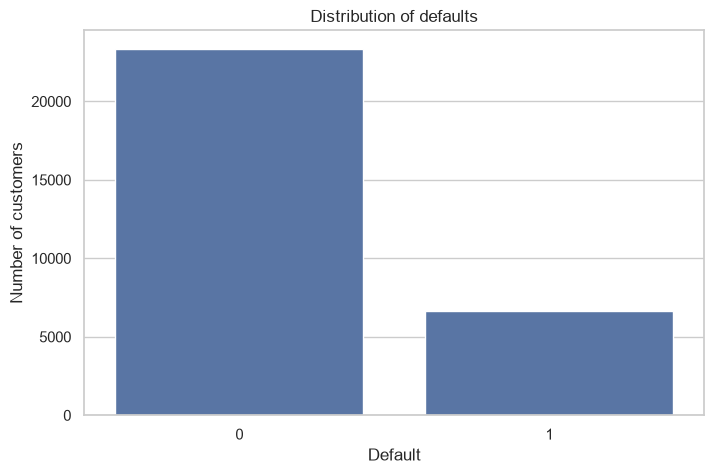

In [7]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x=target_col
)

plt.title("Distribution of defaults")
plt.xlabel("Default")
plt.ylabel("Number of customers")

plt.show()

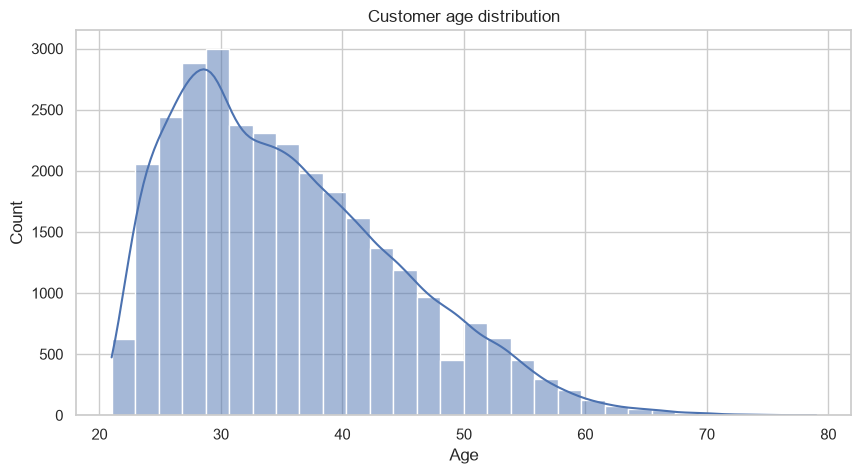

In [8]:
plt.figure(figsize=(10, 5))

sns.histplot(
    data=df,
    x="X5",
    bins=30,
    kde=True
)

plt.title("Customer age distribution")
plt.xlabel("Age")
plt.show()

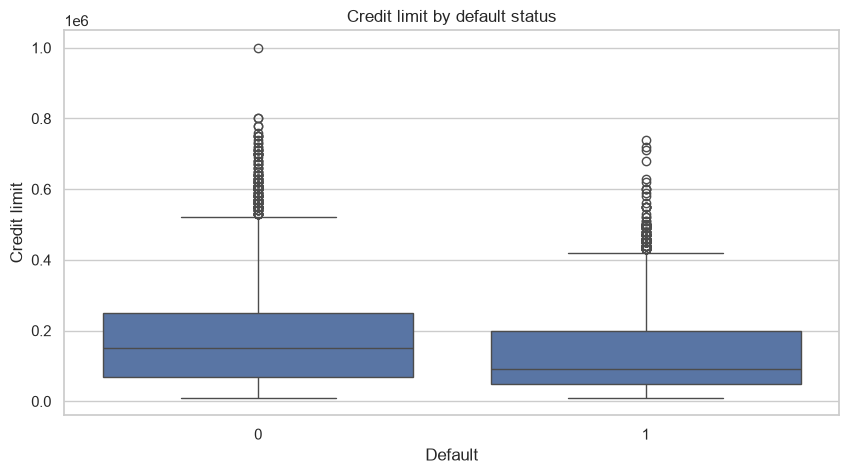

In [14]:
plt.figure(figsize=(10, 5))

sns.boxplot(
    data=df,
    x=target_col,
    y="X1"
)

plt.title("Credit limit by default status")
plt.xlabel("Default")
plt.ylabel("Credit limit")

plt.show()

In [10]:
target_correlation = (
    df.corr(numeric_only=True)[target_col]
    .drop(target_col)
    .sort_values(key=abs, ascending=False)
)

display(target_correlation.to_frame("correlation_with_target"))

,correlation_with_target
X6,0.324794
X7,0.263551
X8,0.235253
X9,0.216614
X10,0.204149
X11,0.186866
X1,-0.153520
X18,-0.072929
X19,-0.058579
X21,-0.056827


In [15]:
payment_analysis = {}

payment_columns = [
    "X6", "X7", "X8",
    "X9", "X10", "X11"
]

for col in payment_columns:

    analysis = (
        df.groupby(col)[target_col]
        .agg(
            customer_count="count",
            default_rate="mean"
        )
        .sort_index()
    )

    analysis["default_rate"] *= 100

    display(analysis.round(2))

,customer_count,default_rate
X6,,
-2,2759,13.23
-1,5686,16.78
0,14737,12.81
1,3688,33.95
2,2667,69.14
3,322,75.78
4,76,68.42
5,26,50.00
6,11,54.55


,customer_count,default_rate
X7,,
-2,3782,18.27
-1,6050,15.97
0,15730,15.91
1,28,17.86
2,3927,55.61
3,326,61.66
4,99,50.51
5,25,60.00
6,12,75.00


,customer_count,default_rate
X8,,
-2,4085,18.53
-1,5938,15.59
0,15764,17.45
1,4,25.00
2,3819,51.56
3,240,57.50
4,76,57.89
5,21,57.14
6,23,60.87


,customer_count,default_rate
X9,,
-2,4348,19.25
-1,5687,15.90
0,16455,18.33
1,2,50.00
2,3159,52.33
3,180,61.11
4,69,66.67
5,35,51.43
6,5,40.00


,customer_count,default_rate
X10,,
-2,4546,19.69
-1,5539,16.19
0,16947,18.85
2,2626,54.19
3,178,63.48
4,84,60.71
5,17,58.82
6,4,75.00
7,58,82.76


,customer_count,default_rate
X11,,
-2,4895,20.04
-1,5740,16.99
0,16286,18.84
2,2766,50.65
3,184,64.13
4,49,63.27
5,13,53.85
6,19,73.68
7,46,82.61


## Outlier analysis

In [12]:
outlier_columns = [
    "X1", "X5",
    "X12", "X13", "X14",
    "X15", "X16", "X17",
    "X18", "X19", "X20",
    "X21", "X22", "X23"
]

outlier_results = []

for col in outlier_columns:

    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)

    IQR = Q3 - Q1

    lower_limit = Q1 - 1.5 * IQR
    upper_limit = Q3 + 1.5 * IQR

    outliers = (
        (df[col] < lower_limit) |
        (df[col] > upper_limit)
    )

    outlier_results.append({
        "variable": col,
        "lower_limit": lower_limit,
        "upper_limit": upper_limit,
        "outlier_count": outliers.sum(),
        "outlier_percentage": outliers.mean() * 100
    })

outlier_summary = pd.DataFrame(outlier_results)

display(
    outlier_summary.sort_values(
        by="outlier_percentage",
        ascending=False
    ).round(2)
)

,variable,lower_limit,upper_limit,outlier_count,outlier_percentage
11,X21,-5279.88,9589.12,2994,9.98
13,X23,-5705.62,9823.38,2958,9.86
12,X22,-5416.00,9700.00,2945,9.82
8,X18,-5009.00,11015.00,2745,9.15
6,X16,-70878.25,122831.75,2725,9.08
9,X19,-5417.50,11250.50,2714,9.05
7,X17,-70657.38,121111.62,2693,8.98
5,X15,-75942.12,132774.88,2622,8.74
10,X20,-5782.50,10677.50,2598,8.66
4,X14,-83581.50,146412.50,2469,8.23


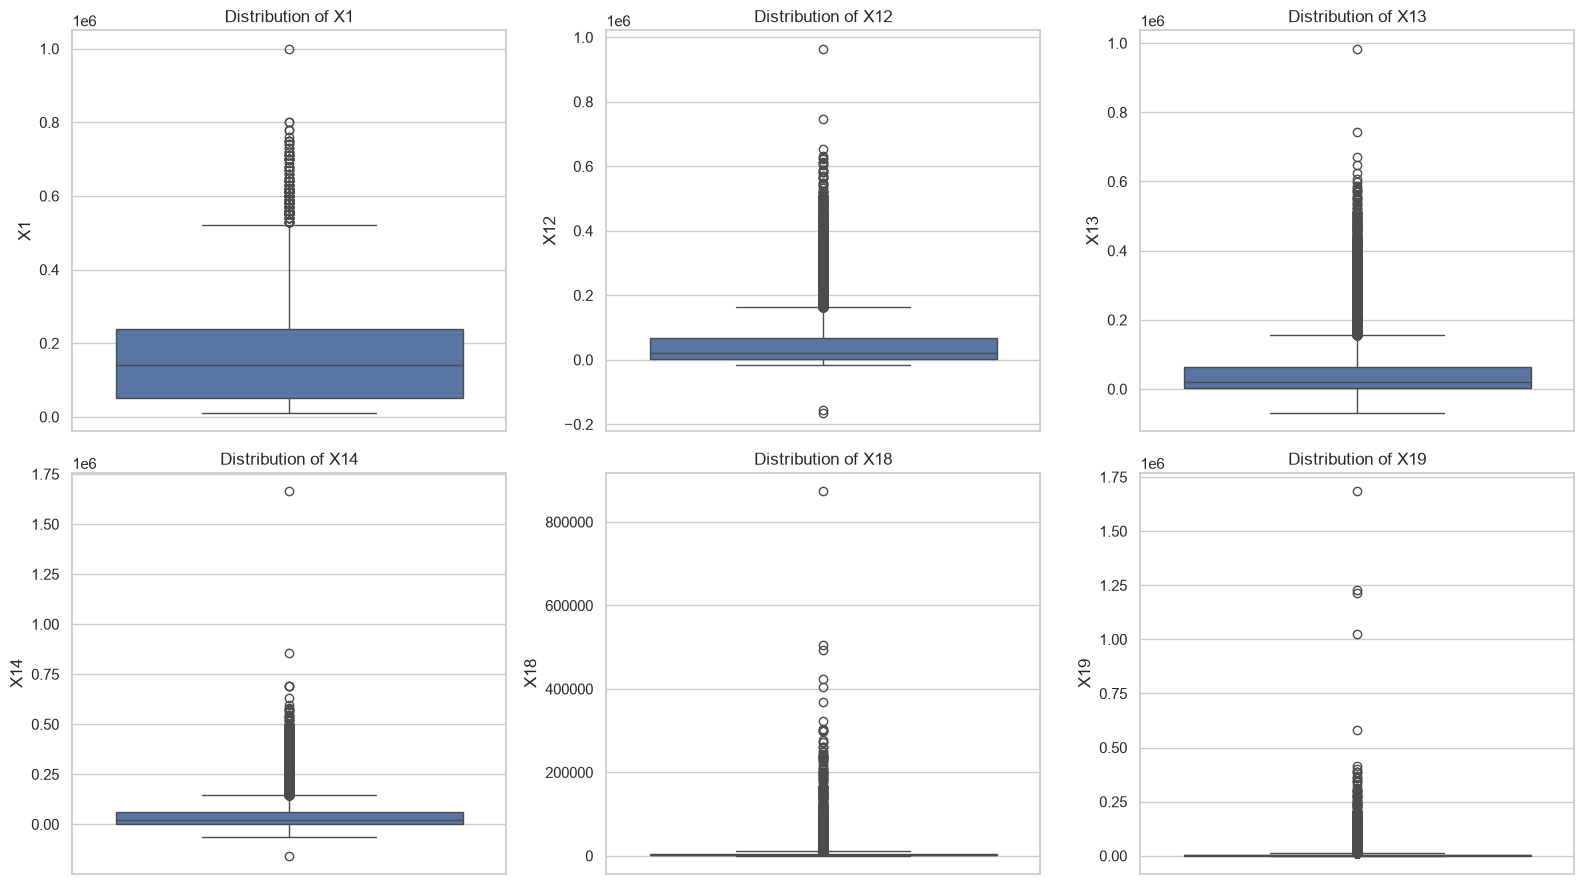

In [13]:
financial_columns = [
    "X1", "X12", "X13",
    "X14", "X18", "X19"
]

fig, axes = plt.subplots(2, 3, figsize=(16, 9))

for col, ax in zip(financial_columns, axes.flatten(), strict=False):
    sns.boxplot(data=df, y=col, ax=ax)
    ax.set_title(f"Distribution of {col}")

plt.tight_layout()
plt.show()

## Initial Conclusions

- The dataset contains 30000 observations and 24 columns
- No missing values were identified
- 35 duplicated records were detected
- The target variable presents class imbalance
- Payment history variables show relevant associations with default
- Financial variables require further investigation due to potential outliers

## Potential Challenges

- Class imbalance
- Outlier treatment
- Feature selection
- Model evaluation using appropriate metrics
- Prevention of data leakage